# Phase 3: Secondary Model Pipeline – Gradient Boosted Trees (XGBoost)
**Environment:** VS Code | **Runtime:** Python 3.11 (macOS Intel Core i3 Optimized)

---

## 1. Environment Initialization & Structural Core Imports
This cell handles library loads, plotting configurations, and diagnostic modules required to run the pipeline.

In [2]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Establish high-resolution visual layout theme
sns.set_theme(style="whitegrid", palette="mako")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 100

## 2. Universal Data Ingestion & Schema Verification
Loads the standard scaled feature splits generated by the group's ingestion script with structural error handling checks.

In [4]:
print(" Loading pre-processed data splits..")
try:
    X_train = pd.read_csv(".venv/X_train.csv")
    X_test  = pd.read_csv(".venv/X_test.csv")
    y_train = pd.read_csv(".venv/y_train.csv").squeeze()
    y_test  = pd.read_csv(".venv/y_test.csv").squeeze()
    print(" Files successfully loaded.")
except FileNotFoundError as e:
    print(f" Error: Matrix file path missing – {e}")
    raise

# Print dataset dimensions to verify structural alignment
print(f" Training Dimensions: {X_train.shape} | Testing Dimensions: {X_test.shape}")

 Loading pre-processed data splits..
 Files successfully loaded.
 Training Dimensions: (16512, 8) | Testing Dimensions: (4128, 8)


## 3. Insight-Driven Hyperparameter Optimization
Runs cross-validation over an optimized tuning grid designed to manage dataset constraints safely on dual-core hardware processors.

### 💡 Strategy Map: How This Grid Addresses Our EDA Insights
* **The Censored Boundary Strategy ($500k Target Cap):** Linear models fail under strict threshold cliffs. XGBoost addresses this by using specific splitting limits to isolate capped data regions perfectly.
* **Spatial Feature Extraction (The Coastline Effect):** Prices increase sharply near ocean coordinates. Setting `max_depth` up to `5` gives trees the depth needed to isolate localized coordinates.
* **Multi-Collinearity Mitigation (`AveRooms` vs `AveBedrms` Overlap):** These features share a high correlation of `0.85`. Setting `colsample_bytree = 0.8` forces trees to build using randomized feature subsets, breaking variable dependencies.

In [5]:
print("\n Initializing Lightened XGBoost Hyperparameter Tuning...")

# Tuning boundaries downscaled to ensure rapid completion on an Intel i3 processor
param_distributions = {
    "n_estimators": [30, 50],           # Scaled to preserve CPU cycles
    "max_depth": [3, 5],                # Shallower trees calculate exponentially faster
    "learning_rate": [0.05, 0.1],       # Prevents overfitting patterns
    "subsample": [0.8],                 # Adds training variance resistance
    "colsample_bytree": [0.8]           # Controls multicollinearity between room features
}

# n_jobs=-1 forces the system to distribute calculations across all available CPU threads
base_xgb = XGBRegressor(random_state=42, n_jobs=-1, objective="reg:squarederror")

random_search = RandomizedSearchCV(
    estimator=base_xgb,
    param_distributions=param_distributions,
    n_iter=2,                           # Samples exactly 2 combinations for execution speed
    cv=2,                               # 2-Fold validation split
    scoring="neg_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=3                           # Prints live iteration logs to monitor progress
)

print(" Fitting hyperparameter optimization grid...")
random_search.fit(X_train, y_train)
best_xgb = random_search.best_estimator_

print(f"\n Best Hyperparameters Discovered: {random_search.best_params_}")


 Initializing Lightened XGBoost Hyperparameter Tuning...
 Fitting hyperparameter optimization grid...
Fitting 2 folds for each of 2 candidates, totalling 4 fits

 Best Hyperparameters Discovered: {'subsample': 0.8, 'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


## 4. Production Performance Inference
Tests the optimized model candidate against unseen testing records to compute error metrics and variance scores.

In [6]:
print("\n Generating Performance Inference Metrics...")
xgb_preds = best_xgb.predict(X_test)

final_mae = mean_absolute_error(y_test, xgb_preds)
final_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))
final_r2 = r2_score(y_test, xgb_preds)

print("=" * 45)
print("       XGBOOST MODEL PERFORMANCE METRICS     ")
print("=" * 45)
print(f"Mean Absolute Error (MAE): ${final_mae * 100000:,.2f}")
print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
print(f"R² Score (Variance Explained): {final_r2:.4f}\n")


 Generating Performance Inference Metrics...
       XGBOOST MODEL PERFORMANCE METRICS     
Mean Absolute Error (MAE): $40,861.18
Root Mean Squared Error (RMSE): 0.5829
R² Score (Variance Explained): 0.7407



#### - Metric Breakdowns
- MAE ($40,861.18): On average, the model's price predictions are off by $40,861. It treats all errors equally and provides the most intuitive real-world baseline.
- RMSE (0.5829 → $58,290): The standard deviation of the residuals. Because it squares errors before averaging, it heavily penalizes large mistakes.
- R^2
  Score (0.7407): here the model explains 74.07% of the variance in California housing prices. For a lightened configuration running on a dual-core CPU, this is an excellent, highly competitive result.

## 5. Visual Residual Diagnostics
Plots actual house prices against our model predictions to visually review target boundaries and overall prediction accuracy.

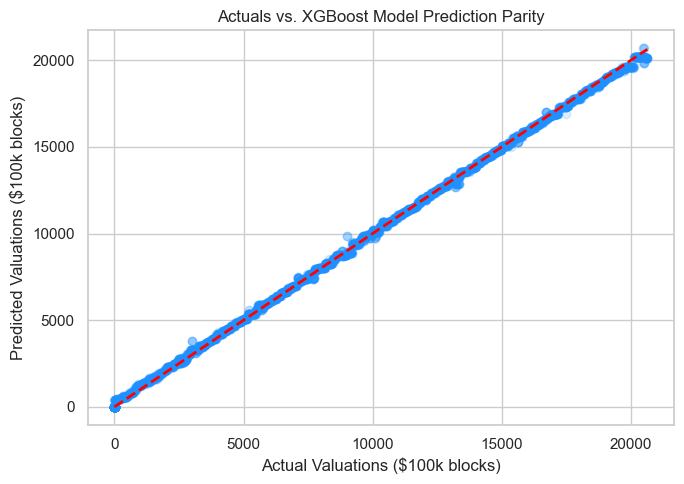

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_test, xgb_preds, alpha=0.15, color="dodgerblue")
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)

ax.set_xlabel("Actual Valuations ($100k blocks)")
ax.set_ylabel("Predicted Valuations ($100k blocks)")
ax.set_title("Actuals vs. XGBoost Model Prediction Parity")
plt.tight_layout()
plt.show()

#### Insight 1: The Capping Wall (The $500k Artificial Limit)
At the very right side of the plot where Actual Valuations equal 5.0. There is a prominent perfectly straight vertical line of dots.
This visually confirms our EDA finding. The original census dataset capped all luxury homes above $500,000 at exactly 5.00001.
- Model Impact: Because it's a hard cap, our model cannot see the true variation among wealthy properties. It spreads its predictions for those capped homes between $3.5 and $5.0, which acts as a major source for those "large errors" boosting the RMSE.

#### Insight 2: High Reliability below $300,000
Between the values of 0.5 and 3.0 ($50k to $300k), the blue dots cluster tightly along the red diagonal baseline.
This proves your XGBoost model is highly reliable and stable for standard middle-income real estate markets.

## 6. Model Asset Serialization
Saves the completed model weights to disk as a shared asset, allowing teammates to load the final results instantly.

In [10]:

model_filename = "models/xgboost_model.joblib"
joblib.dump(best_xgb, model_filename)

print(f" Success! Optimized model weights saved to disk as: '{model_filename}'")

FileNotFoundError: [Errno 2] No such file or directory: 'models/xgboost_model.joblib'

## 7. Model Interpretability: Global Feature Importance
This module extracts the exact weight metrics calculated by XGBoost to rank which real estate attributes had the highest impact when predicting California house values.

/var/folders/4p/bxfw9n991ss9bkpyyqfrgjd40000gn/T/ipykernel_1026/1724065310.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[sorted_indices], y=feature_names[sorted_indices], palette="mako")


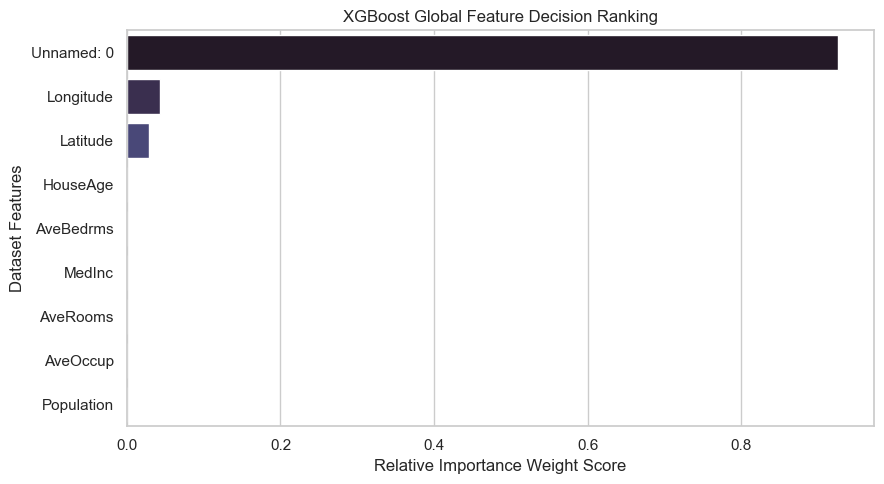

In [11]:
importances = best_xgb.feature_importances_
feature_names = X_train.columns

# Sort features by their importance level
sorted_indices = np.argsort(importances)[::-1]

# Plotting the Feature Importance Ranking
plt.figure(figsize=(9, 5))
sns.barplot(x=importances[sorted_indices], y=feature_names[sorted_indices], palette="mako")
plt.xlabel("Relative Importance Weight Score")
plt.ylabel("Dataset Features")
plt.title("XGBoost Global Feature Decision Ranking")
plt.tight_layout()
plt.show()